## Setup
Load the tools we need and make a `models` folder to save the trained result in.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## The game world
A robot walks on a 4×4 grid, starting top-left and trying to reach the goal at the bottom-right.

`step()` is the rulebook: give it a position and a move, and it returns where you land, the reward, and whether the game ended.

- **Goal:** +1, game over
- **Trap:** -1, game over
- **Any other move:** -0.04, a small cost that rewards short routes
- **Walking into a wall:** you stay put, but still pay the cost

In [2]:
rng = np.random.default_rng(42)

ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]        # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

## Training: learning by trial and error
`Q` is a cheat sheet with one score for every (cell, move) pair. It starts at all zeros, so the robot knows nothing.

- **`epsilon` is the chance of a random move.** It starts at 1 (always exploring) and shrinks each episode, so the robot gradually relies on what it has learned.
- **`alpha` is the learning speed.** Each update moves a score only 15% of the way toward the new estimate.
- **`gamma` is patience.** At 0.95, a future reward counts slightly less than the same reward right now.

After each move, the score is nudged toward:

`target = reward now + gamma × best score from the next cell`

This is how the goal's reward spreads backwards across the grid, one cell at a time.

In [3]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))       # explore: random move
    return int(np.argmax(Q[state]))                  # exploit: best known move

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

## Training curve
Single episodes are noisy, so we plot the average return of the last 100 episodes.

The line should climb as the robot explores less and learns more. The dashed line at 0.8 is the best possible return.

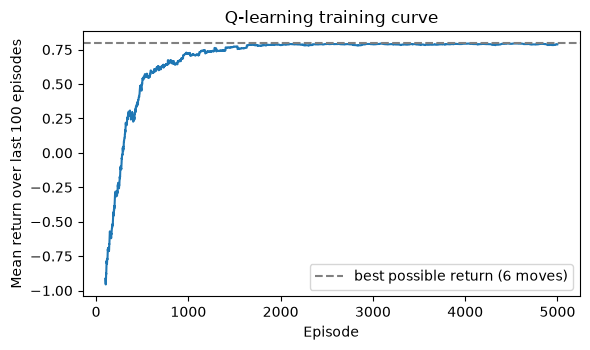

In [4]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

## Testing the learned policy
During training, the robot still makes some random moves, so its training scores understate what it has learned. Here we turn exploration off and always pick the highest-scoring move.

**What to expect:** the best route takes 6 moves, so the return is 5 × (-0.04) + 1 = **0.80**. A 100% success rate with a return of 0.80 means the robot found a shortest route.

In [5]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


## Saving the model
For tabular Q-learning, the Q-table *is* the model. We save it, load it back, and read the best move for each cell. No retraining is needed.

In [6]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)

Q_loaded = np.load(q_path)
policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


## Seeing the policy
Each arrow shows the best move from that cell. Darker green means a higher score, so cells closer to the goal should generally look darker.

Follow the arrows from the top-left: they should lead to the goal without entering the trap.

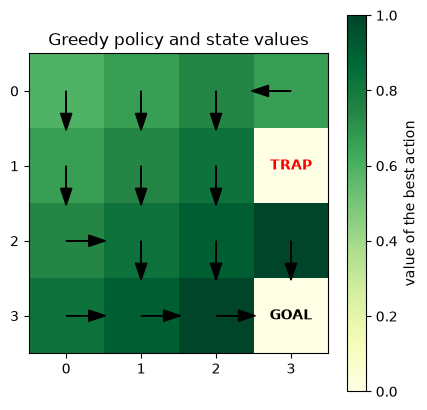

In [7]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values")